# Chapitre 13 - Méthodes à prototypes (cours 1)

Ce premier notebook du chapitre 13 présente les **méthodes à prototypes** pour la
classification :

1. le **K-means** utilisé comme classifieur (section 13.2.1 du livre) ;
2. la **quantification vectorielle par apprentissage** (LVQ, section 13.2.2) ;
3. les **mélanges gaussiens** vus comme des prototypes « souples » (section 13.2.3) ;
4. l'étude comparative « facile / difficile » de la section 13.3.1 (partie K-means et LVQ).

Nous reproduisons les figures 13.1, 13.2 et le panneau de droite de la figure 13.5.
Les plus proches voisins font l'objet du second notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl.plotting import decision_grid
from esl import datasets
from esl import ch13_prototypes as cp
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
set_style()

## 1. Cadre et notations

On dispose de $N$ couples d'apprentissage $(x_1, g_1), \dots, (x_N, g_N)$ où
$x_i \in \mathbb{R}^p$ est un vecteur de caractéristiques et $g_i \in \{1, \dots, K\}$
une étiquette de classe.

Une **méthode à prototypes** résume les données par un petit nombre de points
$m_1, \dots, m_M \in \mathbb{R}^p$, les *prototypes*, chacun muni d'une classe.
Un nouveau point $x$ est affecté à la classe du **prototype le plus proche** :

$$\hat G(x) = \text{classe de } m_{j^*}, \qquad j^* = \arg\min_{j} \|x - m_j\|.$$

La distance est la distance euclidienne, calculée après avoir **standardisé**
chaque variable (moyenne nulle, variance 1 sur l'échantillon d'apprentissage),
pour que des variables mesurées dans des unités différentes pèsent autant.

> **Intuition.** La règle « prototype le plus proche » découpe l'espace en
> **cellules de Voronoï** : la cellule de $m_j$ est l'ensemble des points plus
> proches de $m_j$ que de tous les autres prototypes. Chaque cellule est un polyèdre
> convexe (intersection de demi-espaces $\{x : \|x-m_j\| \le \|x - m_l\|\}$,
> et cette inégalité est linéaire en $x$ après développement des carrés).
> La frontière de décision est donc **linéaire par morceaux**.

Toute la difficulté est de choisir **combien** de prototypes utiliser et **où** les placer.

## 2. Une simulation à trois classes

Pour reproduire l'esprit de la figure 13.1, nous simulons trois classes en
dimension 2, chacune étant un **mélange de gaussiennes** : la classe $k$ possède
10 centres $\mu_{k1}, \dots, \mu_{k,10}$ (tirés autour d'un point de base) ;
une observation de la classe $k$ choisit un centre au hasard puis ajoute un
bruit $\mathcal N(0, \sigma^2 I_2)$.

Comme nous connaissons le modèle, nous pouvons calculer la **règle de Bayes**
$\arg\max_k \Pr(G = k \mid X = x)$ et sa frontière (courbe en pointillés violets
dans les figures).

In [2]:
rng = np.random.RandomState(2)
base = np.array([[-1.5, 1.0], [1.5, 1.0], [0.0, -1.5]])
means3 = [b + 0.8 * rng.randn(10, 2) for b in base]
sigma2_3 = 0.2
X3, y3 = cp.sample_gaussian_mixture(means3, 100, sigma2_3, rng)
X3_test, y3_test = cp.sample_gaussian_mixture(means3, 3000, sigma2_3, rng)
bayes3 = np.mean(cp.mixture_posterior(X3_test, means3, sigma2_3).argmax(1) != y3_test)
print("Apprentissage :", X3.shape, " test :", X3_test.shape)
print("Erreur de Bayes (estimée sur l'échantillon test) : %.3f" % bayes3)

Apprentissage : (300, 2)  test : (9000, 2)
Erreur de Bayes (estimée sur l'échantillon test) : 0.073


Une petite fonction de tracé, réutilisée dans tout le notebook : elle colore les
régions de décision d'un classifieur sur une grille, superpose les données, les
prototypes (gros points cerclés de noir) et la frontière de Bayes.

In [3]:
CMAP3 = ListedColormap(COLORS[:3])
PURPLE = COLORS[6]


def plot_regions(ax, predict, X, y, protos=None, proto_labels=None, bayes=None,
                 xlim=None, ylim=None, n=250, ncls=3):
    xlim = xlim or (X[:, 0].min() - 0.5, X[:, 0].max() + 0.5)
    ylim = ylim or (X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)
    xx, yy, grid = decision_grid(xlim, ylim, n)
    cmap = ListedColormap(COLORS[:ncls])
    Z = predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.arange(ncls + 1) - 0.5, cmap=cmap, alpha=0.15)
    ax.contour(xx, yy, Z, levels=np.arange(ncls) + 0.5, colors="k", linewidths=1)
    if bayes is not None:
        B = bayes(grid).reshape(xx.shape)
        ax.contour(xx, yy, B, levels=np.arange(ncls) + 0.5, colors=PURPLE,
                   linewidths=1.5, linestyles="--")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, s=12, alpha=0.7, vmin=0, vmax=ncls - 1)
    if protos is not None:
        ax.scatter(protos[:, 0], protos[:, 1], c=proto_labels, cmap=cmap, s=90,
                   edgecolors="k", linewidths=1.5, vmin=0, vmax=ncls - 1)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_xlabel("$X_1$")
    ax.set_ylabel("$X_2$")


bayes3_rule = lambda G: cp.mixture_posterior(G, means3, sigma2_3).argmax(1)

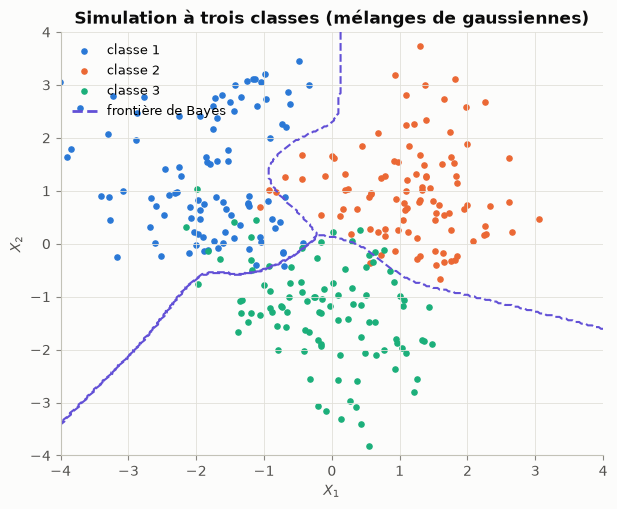

In [4]:
fig, ax = plt.subplots(figsize=(7, 5.5))
for k in range(3):
    m = y3 == k
    ax.scatter(X3[m, 0], X3[m, 1], s=14, color=COLORS[k], label="classe %d" % (k + 1))
xx, yy, grid = decision_grid((-4, 4), (-4, 4), 250)
ax.contour(xx, yy, bayes3_rule(grid).reshape(xx.shape), levels=[0.5, 1.5],
           colors=PURPLE, linestyles="--", linewidths=1.5)
ax.plot([], [], "--", color=PURPLE, label="frontière de Bayes")
ax.set(title="Simulation à trois classes (mélanges de gaussiennes)",
       xlabel="$X_1$", ylabel="$X_2$", xlim=(-4, 4), ylim=(-4, 4))
ax.legend(loc="upper left")
plt.show()

## 3. Le K-means

### 3.1 Le critère

Le K-means (que l'on note ici avec $R$ centres, la lettre $K$ étant réservée au
nombre de classes) cherche $R$ centres $m_1, \dots, m_R$ et une affectation
$C(i) \in \{1, \dots, R\}$ de chaque point à un centre qui minimisent l'**inertie
intra-groupes**

$$J(C, m) = \sum_{i=1}^N \|x_i - m_{C(i)}\|^2 .$$

### 3.2 L'algorithme de Lloyd

Partant de centres initiaux (typiquement $R$ points tirés au hasard parmi les
données), on alterne :

1. **affectation** : à centres fixés, chaque point rejoint le centre le plus proche,
   $C(i) = \arg\min_r \|x_i - m_r\|^2$ ;
2. **mise à jour** : à affectation fixée, chaque centre devient la moyenne de son groupe,
   $m_r = \frac{1}{N_r} \sum_{C(i) = r} x_i$.

On itère jusqu'à ce que les affectations ne changent plus.

**Pourquoi le critère décroît-il ?**

* L'étape 1 minimise $J$ en $C$ à $m$ fixé : chaque terme $\|x_i - m_{C(i)}\|^2$ est
  rendu minimal individuellement, donc $J$ ne peut pas augmenter.
* L'étape 2 minimise $J$ en $m$ à $C$ fixé. En effet, pour un groupe $r$,
  la fonction $m \mapsto \sum_{C(i)=r} \|x_i - m\|^2$ est un polynôme du second degré
  strictement convexe ; son gradient $-2 \sum_{C(i)=r}(x_i - m)$ s'annule en
  $m = \bar x_r$, la moyenne du groupe, qui est donc l'unique minimum.

$J$ décroît à chaque étape et ne prend qu'un nombre fini de valeurs (il y a un
nombre fini d'affectations possibles) : l'algorithme **s'arrête en un nombre fini
d'itérations**, sur un minimum *local* (d'où l'intérêt de plusieurs redémarrages).

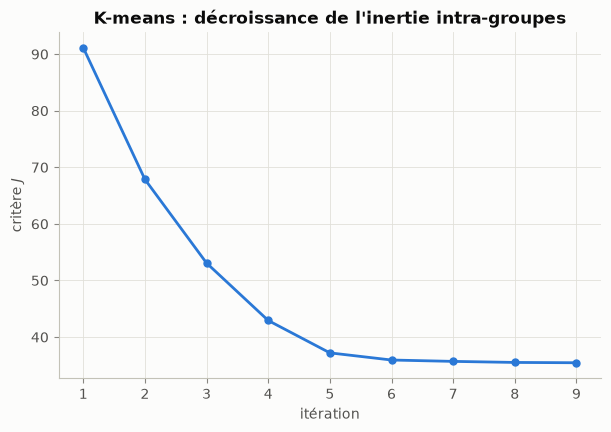

In [5]:
C, lab, inertia, hist = cp.kmeans(X3[y3 == 0], 5, n_init=1, rng=np.random.RandomState(3))
fig, ax = plt.subplots()
ax.plot(np.arange(1, len(hist) + 1), hist, "o-", color=BLUE)
ax.set(title="K-means : décroissance de l'inertie intra-groupes",
       xlabel="itération", ylabel="critère $J$")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.show()

### 3.3 Le K-means comme classifieur

Pour des données **étiquetées**, on procède ainsi :

1. on applique le K-means **séparément dans chaque classe**, avec $R$ prototypes par classe ;
2. chacun des $K \times R$ prototypes reçoit l'étiquette de sa classe ;
3. un nouveau point est classé selon le prototype le plus proche.

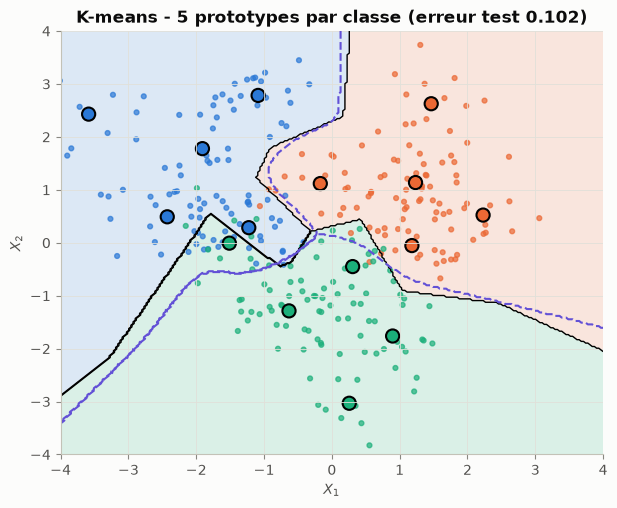

In [6]:
km3 = cp.KMeansClassifier(R=5, rng=np.random.RandomState(0)).fit(X3, y3)
err_km3 = np.mean(km3.predict(X3_test) != y3_test)

fig, ax = plt.subplots(figsize=(7, 5.5))
plot_regions(ax, km3.predict, X3, y3, km3.prototypes_, km3.proto_labels_,
             bayes3_rule, (-4, 4), (-4, 4))
ax.set_title("K-means - 5 prototypes par classe (erreur test %.3f)" % err_km3)
plt.show()

> **Remarque.** Plusieurs prototypes se trouvent tout près de la frontière entre
> classes. C'est le défaut structurel de la méthode : quand on place les prototypes
> d'une classe, **les autres classes n'ont pas leur mot à dire**. Le K-means résume
> bien la distribution de chaque classe, mais il n'est pas conçu pour bien
> *discriminer*.

## 4. LVQ - quantification vectorielle par apprentissage

L'idée de Kohonen est d'utiliser **toutes** les données pour positionner **tous** les
prototypes : un point d'apprentissage *attire* les prototypes de sa classe et
*repousse* les autres.

**Algorithme LVQ1** (algorithme 13.1 du livre, reformulé).

1. Choisir $R$ prototypes initiaux par classe, $m_1(k), \dots, m_R(k)$ (par exemple
   la solution K-means, ou $R$ points tirés au hasard dans la classe $k$).
2. Tirer un point d'apprentissage $x_i$ au hasard (avec remise) et repérer le
   prototype le plus proche, $m_j(k)$.
   * si $g_i = k$ (même classe), on le **rapproche** : $m_j(k) \leftarrow m_j(k) + \epsilon\,(x_i - m_j(k))$ ;
   * si $g_i \ne k$, on l'**éloigne** : $m_j(k) \leftarrow m_j(k) - \epsilon\,(x_i - m_j(k))$.
3. Répéter l'étape 2 en faisant décroître le pas $\epsilon$ vers 0.

> **Intuition.** Le déplacement $\epsilon(x_i - m)$ fait parcourir au prototype une
> fraction $\epsilon$ du segment qui le sépare de $x_i$. Un prototype mal placé près de
> la frontière est sans cesse repoussé par les points de l'autre classe : il s'en
> écarte.

> **Remarque (pas d'apprentissage).** Comme pour le gradient stochastique
> (section 11.4), on prend des pas $\epsilon_t \to 0$. La théorie de
> l'approximation stochastique demande classiquement $\sum_t \epsilon_t = \infty$
> (pour pouvoir aller loin) et $\sum_t \epsilon_t^2 < \infty$ (pour que le bruit
> s'éteigne). Ici nous utilisons simplement une décroissance linéaire
> $\epsilon_t = \epsilon_0 (1 - t/T)$ sur un nombre fixé $T$ d'itérations.

Un défaut de LVQ : elle est définie par un **algorithme** et non par un critère à
optimiser, ce qui rend ses propriétés difficiles à analyser.

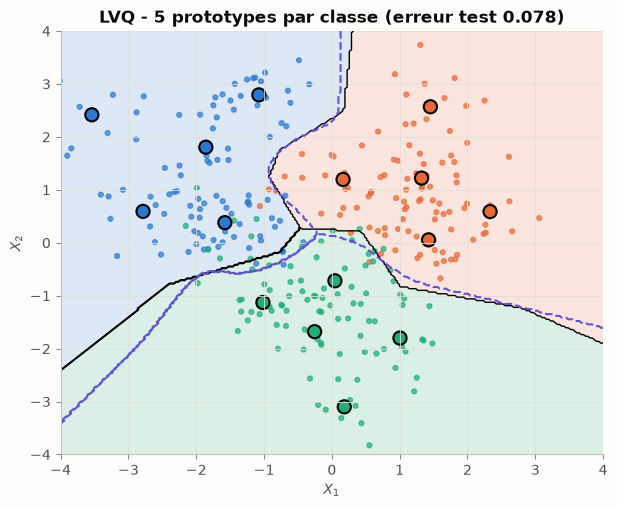

In [7]:
lvq3 = cp.LVQClassifier(R=5, eps0=0.1, rng=np.random.RandomState(0)).fit(X3, y3)
err_lvq3 = np.mean(lvq3.predict(X3_test) != y3_test)

fig, ax = plt.subplots(figsize=(7, 5.5))
plot_regions(ax, lvq3.predict, X3, y3, lvq3.prototypes_, lvq3.proto_labels_,
             bayes3_rule, (-4, 4), (-4, 4))
ax.set_title("LVQ - 5 prototypes par classe (erreur test %.3f)" % err_lvq3)
plt.show()

Visualisons le **déplacement** de chaque prototype entre la solution K-means
(point de départ) et la solution LVQ (flèche).

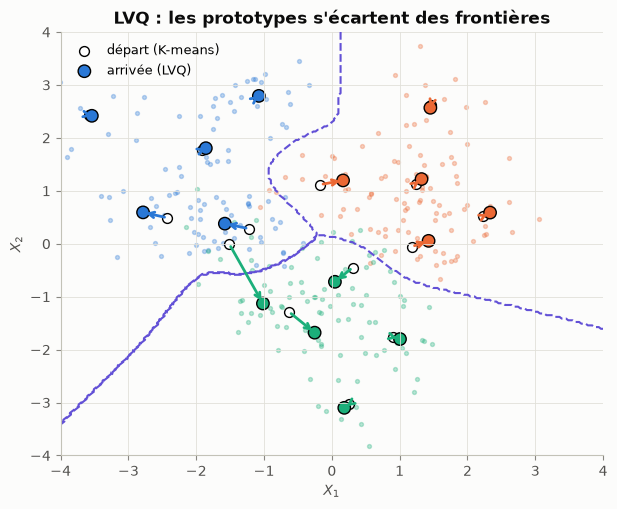

In [8]:
fig, ax = plt.subplots(figsize=(7, 5.5))
for k in range(3):
    m = y3 == k
    ax.scatter(X3[m, 0], X3[m, 1], s=8, color=COLORS[k], alpha=0.3)
P0, P1 = lvq3.init_prototypes_, lvq3.prototypes_
for a, b, k in zip(P0, P1, lvq3.proto_labels_):
    ax.annotate("", xy=b, xytext=a,
                arrowprops=dict(arrowstyle="->", color=COLORS[k], lw=2))
ax.scatter(P0[:, 0], P0[:, 1], c="white", edgecolors="k", s=50, label="départ (K-means)")
ax.scatter(P1[:, 0], P1[:, 1], c=[COLORS[k] for k in lvq3.proto_labels_],
           edgecolors="k", s=80, label="arrivée (LVQ)")
ax.contour(xx, yy, bayes3_rule(grid).reshape(xx.shape), levels=[0.5, 1.5],
           colors=PURPLE, linestyles="--", linewidths=1.5)
ax.set(title="LVQ : les prototypes s'écartent des frontières",
       xlabel="$X_1$", ylabel="$X_2$", xlim=(-4, 4), ylim=(-4, 4))
ax.legend(loc="upper left")
plt.show()

In [9]:
print("Erreur de Bayes   : %.3f" % bayes3)
print("K-means (R = 5)   : %.3f" % err_km3)
print("LVQ1    (R = 5)   : %.3f" % err_lvq3)

Erreur de Bayes   : 0.073
K-means (R = 5)   : 0.102
LVQ1    (R = 5)   : 0.078


## 5. Mélanges gaussiens : des prototypes « souples »

### 5.1 Le modèle

On peut aussi modéliser la densité de chaque classe $k$ par un **mélange** de $R$
gaussiennes :

$$f_k(x) = \sum_{r=1}^R w_{kr}\, \phi(x; \mu_{kr}, \Sigma), \qquad w_{kr} \ge 0,\ \sum_r w_{kr} = 1,$$

où $\phi(\cdot; \mu, \Sigma)$ est la densité gaussienne de moyenne $\mu$ et de
covariance $\Sigma$. Nous prenons, comme le livre pour la figure 13.2, une **même
covariance** $\Sigma$ pour toutes les composantes. Chaque $\mu_{kr}$ joue le rôle
d'un prototype, et $\Sigma$ décrit la « forme » autour de chaque prototype.

Avec les proportions de classes $\pi_k$, la formule de Bayes donne les
probabilités a posteriori

$$\hat p_k(x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^K \pi_l f_l(x)}$$

(cf. éq. (12.60) du livre) et l'on classe par $\hat G(x) = \arg\max_k \hat p_k(x)$.
Ces probabilités varient **continûment** avec $x$ : les frontières sont lisses,
contrairement aux frontières polygonales du K-means.

### 5.2 L'algorithme EM (rappel)

Maximiser directement la vraisemblance d'un mélange est difficile (le logarithme
d'une somme ne se simplifie pas). L'algorithme **EM** (*Expectation–Maximisation*)
contourne la difficulté en imaginant une variable cachée : la composante $r$ dont
provient chaque observation. Si on la connaissait, l'estimation serait facile
(moyennes et covariance empiriques par composante). EM alterne :

* **étape E** : on calcule, avec les paramètres courants, la *responsabilité* de
  chaque composante $r$ de la classe $g_i$ pour l'observation $i$,
  $$\gamma_{ir} = \frac{w_{g_i r}\,\phi(x_i; \mu_{g_i r}, \Sigma)}{\sum_{r'} w_{g_i r'}\,\phi(x_i; \mu_{g_i r'}, \Sigma)} ;$$
* **étape M** : on ré-estime les paramètres comme si les $\gamma_{ir}$ étaient des
  poids connus :
  $$\mu_{kr} = \frac{\sum_{i : g_i = k} \gamma_{ir} x_i}{\sum_{i : g_i = k} \gamma_{ir}}, \qquad
  \Sigma = \frac1N \sum_{i} \sum_{r} \gamma_{ir} (x_i - \mu_{g_i r})(x_i - \mu_{g_i r})^T, \qquad
  w_{kr} = \frac{\sum_{i : g_i = k}\gamma_{ir}}{N_k}.$$

On montre (chapitre 8 du livre) que chaque itération **fait croître la
vraisemblance**.

> **À retenir (K-means et EM).** Les deux algorithmes ont la même structure :
> l'étape d'affectation du K-means est une version « dure » de l'étape E (chaque point
> appartient à 100 % à un seul groupe), et la mise à jour des centres est une étape M
> avec des poids 0/1. On dit que le mélange gaussien fait un regroupement **souple**
> (*soft clustering*). L'exercice 13.1 montre que les deux coïncident quand la variance
> des composantes tend vers 0.

### 5.3 Les données « mixture » du chapitre 2

Nous reprenons la simulation à deux classes du chapitre 2 : 100 points par classe,
chaque classe étant un mélange de 10 gaussiennes de variance $\sigma^2 = 1/5$
autour de centres $m_{k1}, \dots, m_{k,10}$ fournis avec les données. Connaissant ce
modèle, nous simulons un grand échantillon test (10 000 points) pour estimer les
erreurs.

In [10]:
mix = datasets.load_mixture_example()
Xm, ym = mix["x"], mix["y"]
means_m = [mix["means"][:10], mix["means"][10:]]
Xm_test, ym_test = cp.sample_gaussian_mixture(means_m, 5000, 0.2, np.random.RandomState(0))
post_test = cp.mixture_posterior(Xm_test, means_m, 0.2)
bayes_m = np.mean(post_test.argmax(1) != ym_test)
# la grille du livre fournit les probabilités de Bayes : on vérifie notre formule
post_grid = cp.mixture_posterior(mix["xnew"], means_m, 0.2)[:, 1]
print("écart max avec les probabilités fournies :", np.abs(post_grid - mix["prob"]).max())
print("Erreur de Bayes estimée : %.3f" % bayes_m)

écart max avec les probabilités fournies : 4.218847493575595e-15
Erreur de Bayes estimée : 0.210


### 5.4 Figure 13.2 : K-means contre mélange gaussien

Nous ajustons d'abord le classifieur K-means à 5 prototypes par classe, puis le
mélange gaussien à 5 composantes par classe, **initialisé par la solution K-means**.

In [11]:
km_m = cp.KMeansClassifier(R=5, rng=np.random.RandomState(0)).fit(Xm, ym)
gm_m = cp.GaussianMixtureClassifier(R=5, rng=np.random.RandomState(0)).fit(Xm, ym)
bayes_m_rule = lambda G: cp.mixture_posterior(G, means_m, 0.2).argmax(1)
lims = ((-2.6, 4.2), (-2.0, 2.9))

res = {}
for name, clf in [("K-means", km_m), ("Mélange gaussien", gm_m)]:
    res[name] = (np.mean(clf.predict(Xm) != ym), np.mean(clf.predict(Xm_test) != ym_test))
    print("%-17s erreur apprentissage %.3f   erreur test %.3f" % (name, *res[name]))

K-means           erreur apprentissage 0.170   erreur test 0.244
Mélange gaussien  erreur apprentissage 0.165   erreur test 0.217


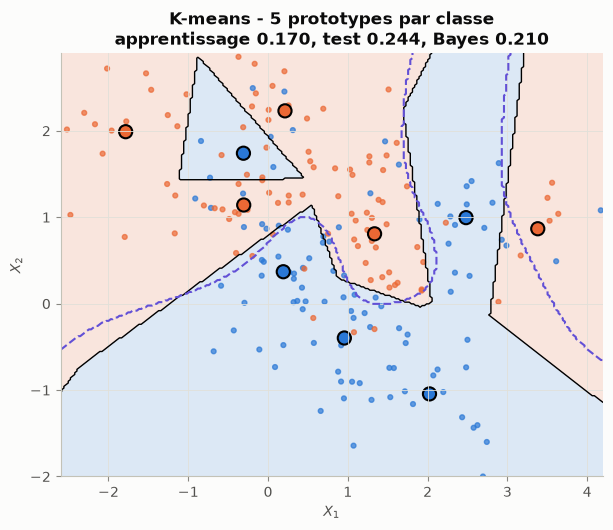

In [12]:
fig, ax = plt.subplots(figsize=(7, 5.5))
plot_regions(ax, km_m.predict, Xm, ym, km_m.prototypes_, km_m.proto_labels_,
             bayes_m_rule, *lims, ncls=2)
ax.set_title("K-means - 5 prototypes par classe\napprentissage %.3f, test %.3f, Bayes %.3f"
             % (*res["K-means"], bayes_m))
plt.show()

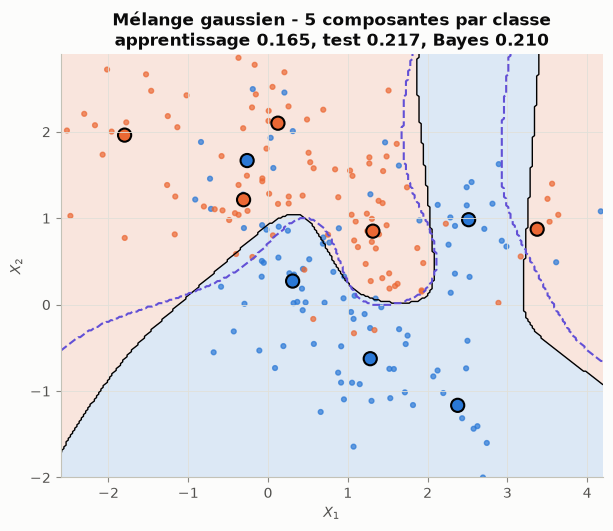

In [13]:
fig, ax = plt.subplots(figsize=(7, 5.5))
plot_regions(ax, gm_m.predict, Xm, ym, gm_m.means_, gm_m.labels_,
             bayes_m_rule, *lims, ncls=2)
ax.set_title("Mélange gaussien - 5 composantes par classe\napprentissage %.3f, test %.3f, Bayes %.3f"
             % (*res["Mélange gaussien"], bayes_m))
plt.show()

Les deux frontières sont proches, mais celle du mélange est **lisse**. Les
prototypes occupent à peu près les mêmes positions (EM est parti du K-means).

Notons la zone au nord-ouest : les deux méthodes y placent un prototype bleu, ce qui
est une erreur (la règle de Bayes y prédit plutôt orange). Le K-means, qui ne
regarde que la distance au prototype le plus proche, est obligé de lui attribuer
une région ; le mélange, qui pondère chaque composante par son poids $w_{kr}$ et
tient compte de toutes les composantes, peut en grande partie l'ignorer.

Vérifions la propriété fondamentale d'EM : la log-vraisemblance (des données dans
leur classe) croît à chaque itération.

In [ ]:
fig, ax = plt.subplots()
ax.plot(np.arange(1, len(gm_m.loglik_) + 1), gm_m.loglik_, "o-", color=BLUE, ms=3)
ax.set(title="EM : croissance de la log-vraisemblance",
       xlabel="itération", ylabel="log-vraisemblance")
plt.show()